# Survival Analysis

When we are testing a new medical treatment regimen, we’re not only interested in whether the treatment works or not. What we want is the probability of how long this treatment will remain effective. In other words, let’s say we have a cancer drug: we don’t just want to know whether or not people survive when on this medication, but rather the probability of longevity, i.e., how long they are likely to survive if they are on this treatment. That’s the fundamental idea behind survival analysis. In this approach, we try to measure "time-to-event" as a set of probabilities and estimate the chances of a particular event happening over time.

## Censored data

Imagine a clinical trial where a patient moves away, drops out of the study, or is still alive and cancer-free when the research period officially concludes. We don’t know their exact long-term outcome, but we do know they survived up to that specific point. Standard statistical methods would throw out or skew this incomplete data, but survival analysis ingeniously incorporates these "censored" observations—meaning that instead of throwing away incomplete records or making false assumptions, it makes full use of every bit of available data. In addition to maximally utilizing data, censoring ensures the elimination of hidden biases. For instance, if people dropped out because they felt better and moved on, throwing them out would make the drug look worse than it is. Conversely, if sicker people dropped out, keeping them out artificially inflates success rates. Censoring accounts for when people leave without assuming why they left.

## Types of Censoring

Not all censoring looks the same, and survival analysis generally classifies missing data into three distinct categories. **Right-censoring** is by far the most common; this happens when a study ends or a participant drops out before the event occurs, meaning we only know their survival time is at least as long as the time they were observed. **Left-censoring** occurs in the opposite scenario, where the target event actually happened before the observation period even began, so we only know it occurred sometime prior to a certain point. Finally, **interval-censoring** happens when subjects are not monitored continuously but instead checked in periodically (like during medical check-ups every six months), meaning we know the event happened, but only that it occurred somewhere within a specific time window between two visits.

## Understanding censoring

To better understand the concept of censoring, let’s start with an intuitive example. Imagine we monitor different users over a period of two years to see when they replace their mobile phone batteries.

- The Trace Ends Early or Outlasts the Study: Right-Censoring happens in two main ways: either a user's battery is still working perfectly fine when the 24-month study officially ends, or a user drops out early—such as by upgrading to a brand-new phone or losing their phone at month 14. In these cases, the target event (battery replacement due to wear) didn't happen while we were watching. We only know that the battery survived at least up to that endpoint (24 months or month 14), after which we lose track of its future. (Meanwhile, users who actually replace their worn-out batteries during the study give us exact event times).

- It Failed Before We Checked (Left-Censoring): What if a user's phone is checked 6 months into the study, and we discover the battery already died sometime before that check? We don't know the exact moment the failure happened, only that it occurred before month 6.

- It Happened in a Blind Window (Interval-Censoring): Suppose a user is checked periodically—their phone was checked at month 10 and the battery was fine, but when checked again at month 15, we find the battery was replaced. We don't know the exact time of replacement, only that it happened somewhere within that 5-month window between our checks.

In [1]:
#| include: false
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
#| include: false
install.packages("kableExtra")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘svglite’




user_id,time_start,time_end,status_code
1,0,12.0,1
2,0,24.0,0
3,0,8.5,1
4,0,14.2,0
5,0,18.2,1
6,0,6.0,0
7,0,6.0,1
8,10,15.0,1
9,12,20.0,1
10,0,24.0,0


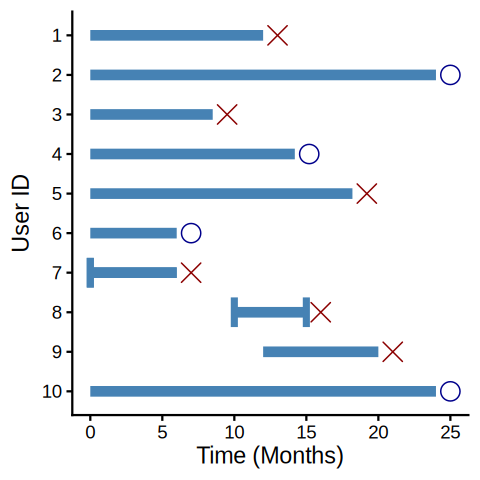

In [14]:
#| fig-cap: "Plot showing survival events based on the table on the left. `X` indicates occurence of the event that is the phone battery was replaced. Eight out of ten users show right censoring, users ID 7 and ID 8 depict left and interval censoring, respectively."
#| label: fig-survival-taxonomy
#| layout: [[50,50]]
#| warning: false
#| message: false
#| echo: false
options(repr.plot.width = 4, repr.plot.height = 4)

library(ggplot2)
library(dplyr)
library(kableExtra)
library(IRdisplay)

# 1. Create the complete 10-user masterclass data frame
battery_df <- data.frame(
  user_id = 1:10,
  time_start = c(0, 0, 0, 0, 0, 0, 0, 10.0, 12.0, 0),
  time_end   = c(12.0, 24.0, 8.5, 14.2, 18.2, 6.0, 6.0, 15.0, 20.0, 24.0),
  status_code = c(1, 0, 1, 0, 1, 0, 2, 3, 1, 0),
  # 1 = Exact Event, 0 = Right-Censored, 2 = Left-Censored, 3 = Interval, 4 = Competing Risk
  censoring_type = factor(
    c("Exact Event", "Right-Censored", "Exact Event",
      "Right-Censored", "Exact Event", "Right-Censored",
      "Left-Censored", "Interval-Censored", "Left-Truncated", "Right-Censored"),
    levels = c("Exact Event", "Right-Censored", "Left-Censored", "Interval-Censored", "Left-Truncated", "Competing Risk")
  ),
  story = c(
    "Replaced battery at month 12 because it degraded.",
    "Study ended at 24 months. Phone was still working fine!",
    "Heavy gamer; replaced battery early at month 8.5.",
    "Upgraded to a new phone at month 14 just for a better camera.",
    "Replaced battery at month 18.2.",
    "Lost their phone at month 6; dropped out of the study.",
    "Battery was already degraded when checked at month 6.",
    "Battery was good at month 10, but failed by inspection at month 15.",
    "Joined study late at month 12 with working phone; battery failed at month 20.",
    "Study ended at 24 months. Phone was still working fine!"
  )
)

# Reverse user_id factor so User 1 appears at the top of the plot
battery_df$user_factor <- factor(
  battery_df$user_id,
  levels = rev(battery_df$user_id)
)

#### Show table ####
html_table <- battery_df |>
  select("user_id",	"time_start",	"time_end",	"status_code") |>
  mutate(status_code = if_else(status_code %in% c(2, 3), 1, status_code)) |>
  kable(format = "html") |>
  kable_styling(
    bootstrap_options = c("bordered", "hover", "condensed"),
    full_width = FALSE
  )

display_html(paste(html_table, collapse = "\n"))
#### Done table ####

# 2. Create the Enhanced Swimmer Plot
ggplot(battery_df, aes(y = user_factor)) +
  # Draw baseline tracking lines from time_start to time_end
  geom_segment(aes(x = time_start, xend = time_end, yend = user_factor),
               color = "steelblue", linewidth = 3) +

  # Uncertainty span bars for Interval & Left censoring
  geom_errorbar(data = subset(battery_df, status_code == 3),
                aes(xmin = time_start, xmax = time_end, y = user_factor),
                orientation = "y",
                width = 0.75, color = "steelblue", linewidth = 2) +
  geom_segment(data = subset(battery_df, status_code == 2),
             aes(x = time_start, xend = time_end, y = user_factor, yend = user_factor),
             color = "steelblue", linewidth = 3) +

  # Single vertical tick aligning correctly with User 7
  geom_errorbar(data = subset(battery_df, status_code == 2),
                aes(xmin = time_start, xmax = time_start, y = user_factor),
                orientation = "y", width = 0.75, color = "steelblue", linewidth = 2) +

  # Exact Events & Left-Truncated events (Red Dots)
  geom_point(data = subset(battery_df, status_code %in% c(1)),
             aes(x = time_end + 1), color = "darkred", size = 5, shape = 4) +

  # Right-Censored (Blue Plus Signs)
  geom_point(data = subset(battery_df, status_code == 0),
             aes(x = time_end + 1), color = "darkblue", size = 5, shape = 1) +

  # Left-Censored / Interval endpoints
  geom_point(data = subset(battery_df, status_code %in% c(2,3)),
             aes(x = time_end + 1), color = "darkred", size = 5, shape = 4) +

  # Labels and Theme
  labs(
    x = "Time (Months)",
    y = "User ID"
  ) +
  theme_classic(base_size = 14)

## Calculating survival probabilities

Using the above data, we'll now calculate the survival probability over different time points. For this analysis, to keep things simple, we'll focus on exact events and right-censored data points (tracking when users drop out or the study ends), while setting aside users with ID 7 and 8 (the left- and interval-censored cases) which require special handling.

The following formula is used to compute probabilities at each event.
$$\text{New Probability} = \text{Previous Probability} \times \left(1 - \frac{\text{Number of Failures}}{\text{Number at Risk}}\right)$$
The starting probability is 1.0, indicating a 100% survival probability at time $t=0$.

month,survival_probability,calculation_step
<dbl>,<dbl>,<chr>
0.0,1.0000,Starting pool (100%)
8.5,0.8750,1.0000 × (1 - 1/8)
12.0,0.7500,0.8750 × (1 - 1/7)
18.2,0.5625,0.7500 × (1 - 1/4)
20.0,0.3750,0.5625 × (1 - 1/3)
24.0,0.3750,No new events (carried forward)


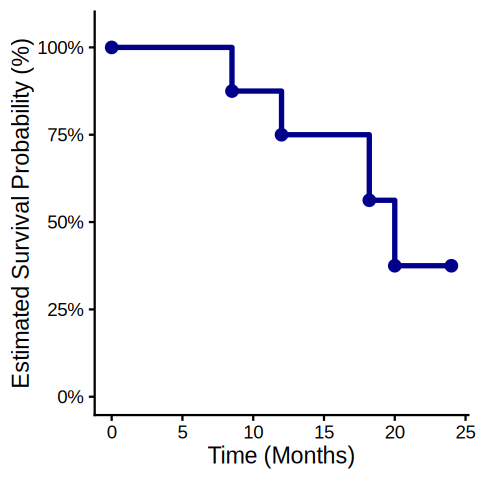

In [13]:
#| fig-cap: "Survival probabilities at each event based on Kaplan-Meier formula."
#| label: fig-survival-probs
#| layout: [[50,50]]
#| warning: false
#| message: false
#| echo: false

options(repr.plot.width = 4, repr.plot.height = 4)

library(ggplot2)
library(dplyr)

# 1. Identify exact event times (excluding left/interval censored users 7 & 8)
event_times <- battery_df %>%
  filter(status_code == 1) %>%
  pull(time_end) %>%
  unique() %>%
  sort()

# 2. Set up vectors to store results
months <- c(0, event_times)
probs <- numeric(length(months))
calc_steps <- character(length(months))

# Initial state at month 0
probs[1] <- 1.0
calc_steps[1] <- "Starting pool (100%)"

current_prob <- 1.0

# 3. Loop through each event time to calculate and build formula text automatically
for (i in seq_along(event_times)) {
  t <- event_times[i]

  # Count active users at risk at time t
  at_risk <- sum(battery_df$time_end >= t)

  # Count exact failures at time t
  failures <- sum(battery_df$time_end == t & battery_df$status_code == 1)

  prev_prob <- current_prob

  if (at_risk > 0) {
    current_prob <- current_prob * (1 - (failures / at_risk))
  }

  # Store results
  probs[i + 1] <- current_prob

  # Automatically generate the formula string using current numbers
  calc_steps[i + 1] <- sprintf("%.4f × (1 - %d/%d)", prev_prob, failures, at_risk)
}

# 4. Create the final data frame
surv_steps <- data.frame(
  month = months,
  survival_probability = probs,
  calculation_step = calc_steps
)

# 5. Add a final tracking row for month 24 (study end)
surv_steps <- rbind(
  surv_steps,
  data.frame(
    month = 24,
    survival_probability = tail(surv_steps$survival_probability, 1),
    calculation_step = "No new events (carried forward)"
  )
)
surv_steps
# 5. Plot the intuitive step curve using standard ggplot2
ggplot(surv_steps, aes(x = month, y = survival_probability)) +
  geom_step(color = "darkblue", linewidth = 1.5, direction = "hv") +
  geom_point(color = "darkblue", size = 3) +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1.05)) +
  labs(
    x = "Time (Months)",
    y = "Estimated Survival Probability (%)"
  ) +
  theme_classic(base_size = 14)

The idea behind the **Kaplan-Meier method** is that we keep track of two things:
1) How many events occur at a given time point.
2) How many subjects are still at risk right at that moment.

Based on these two factors, the formula gives us the cumulative survival probability across different time points.

## The `survival` package

Built specifically to handle complex timelines and censored data, the `survival` R package provides the core computational engine for survival analysis. In conjunction with the `survminer` package, it forms a robust toolkit for survival analysis. Both these packages can be installed by running `install.packages(c("survival", "survminer"))`.

The `survival` package also has the `lung` dataset containing observations for subjects with advanced lung cancer from the North Central Cancer Treatment Group ([reference](https://doi.org/10.1200/JCO.1994.12.3.601)). For survival analysis, we need two core columns from this dataset.
1) time - survival time in days.
2) status - censoring status (1=censored and 2=dead).

The remaining columns can be used to perform covariate analysis, as we'll see later.

In [5]:
#| include: false
#install.packages(c("survival", "survminer"))
install.packages("survival")
install.packages("survminer")



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘car’, ‘rstatix’, ‘ggpubr’




In [6]:
#| message: false
#| warning: false
library(survival)
library(survminer)
head(lung)

Loading required package: ggpubr


Attaching package: ‘survminer’


The following object is masked from ‘package:survival’:

    myeloma




,inst,time,status,age,sex,ph.ecog,ph.karno,pat.karno,meal.cal,wt.loss
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3,306,2,74,1,1,90,100,1175,NA
2,3,455,2,68,1,0,90,90,1225,15
3,3,1010,1,56,1,0,90,90,NA,15
4,5,210,2,57,1,1,90,60,1150,11
5,1,883,2,60,1,0,100,90,NA,0
6,12,1022,1,74,1,1,50,80,513,0


Ignoring unknown labels:
• colour : "Strata"


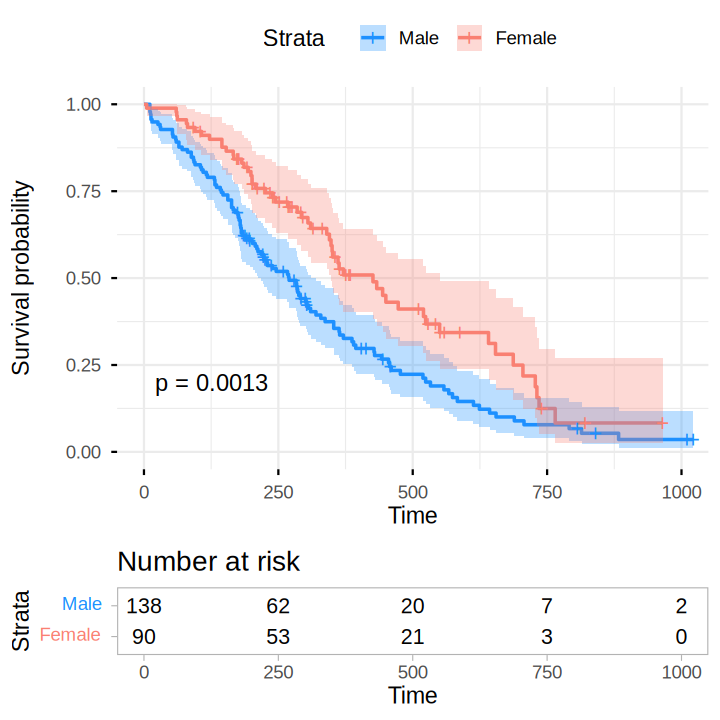

In [56]:
#| fig-cap: "Kaplan–Meier survival curves stratified by sex in the lung cancer dataset."
#| label: fig-km-plot
#| warning: false
#| message: false

# Create the Surv object and fit the Kaplan-Meier model
km_fit <- survfit(Surv(time, status==2) ~ sex, data = lung)

options(repr.plot.width = 6, repr.plot.height = 6)
# Plot the survival curves with a risk table and p-value
ggsurvplot(
  km_fit,
  data = lung,
  pval = TRUE,             # Adds the log-rank test p-value
  conf.int = TRUE,         # Adds confidence intervals
  risk.table = TRUE,       # Adds risk table below the plot
  legend.labs = c("Male", "Female"),
  palette = c("dodgerblue", "salmon"),
  ggtheme = theme_minimal(base_size = 14),
  tables.theme = theme_light(base_size = 14) + theme(panel.grid = element_blank()))


In [34]:
packageVersion("ggplot2")
packageVersion("survminer")
packageVersion("ggpubr")

[1] ‘4.0.3’

[1] ‘0.5.2’

[1] ‘1.0.0’

In [14]:
# Compare raw status vs what Surv() outputted
head(data.frame(
  raw_time = lung$time,
  raw_status = lung$status,
  surv_object = s
), 10)

,raw_time,raw_status,surv_object
,<dbl>,<dbl>,<Surv>
1,306,2,"306, 1"
2,455,2,"455, 1"
3,1010,1,"1010, 0"
4,210,2,"210, 1"
5,883,2,"883, 1"
6,1022,1,"1022, 0"
7,310,2,"310, 1"
8,361,2,"361, 1"
9,218,2,"218, 1"


In [ ]:
log_rank_test <- survdiff(Surv(time, status) ~ sex, data = lung)
print(log_rank_test)

Call:
survdiff(formula = Surv(time, status) ~ sex, data = lung)

        N Observed Expected (O-E)^2/E (O-E)^2/V
sex=1 138      112     91.6      4.55      10.3
sex=2  90       53     73.4      5.68      10.3

 Chisq= 10.3  on 1 degrees of freedom, p= 0.001 


In [ ]:
# Fit the Cox model with multiple predictors
cox_fit <- coxph(Surv(time, status) ~ age + sex + ph.ecog, data = lung)

# View the model summary and hazard ratios
summary(cox_fit)

Call:
coxph(formula = Surv(time, status) ~ age + sex + ph.ecog, data = lung)

  n= 227, number of events= 164 
   (1 observation deleted due to missingness)

             coef exp(coef)  se(coef)      z Pr(>|z|)    
age      0.011067  1.011128  0.009267  1.194 0.232416    
sex     -0.552612  0.575445  0.167739 -3.294 0.000986 ***
ph.ecog  0.463728  1.589991  0.113577  4.083 4.45e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

        exp(coef) exp(-coef) lower .95 upper .95
age        1.0111     0.9890    0.9929    1.0297
sex        0.5754     1.7378    0.4142    0.7994
ph.ecog    1.5900     0.6289    1.2727    1.9864

Concordance= 0.637  (se = 0.025 )
Likelihood ratio test= 30.5  on 3 df,   p=1e-06
Wald test            = 29.93  on 3 df,   p=1e-06
Score (logrank) test = 30.5  on 3 df,   p=1e-06


        chisq df    p
age     0.188  1 0.66
sex     2.305  1 0.13
ph.ecog 2.054  1 0.15
GLOBAL  4.464  3 0.22


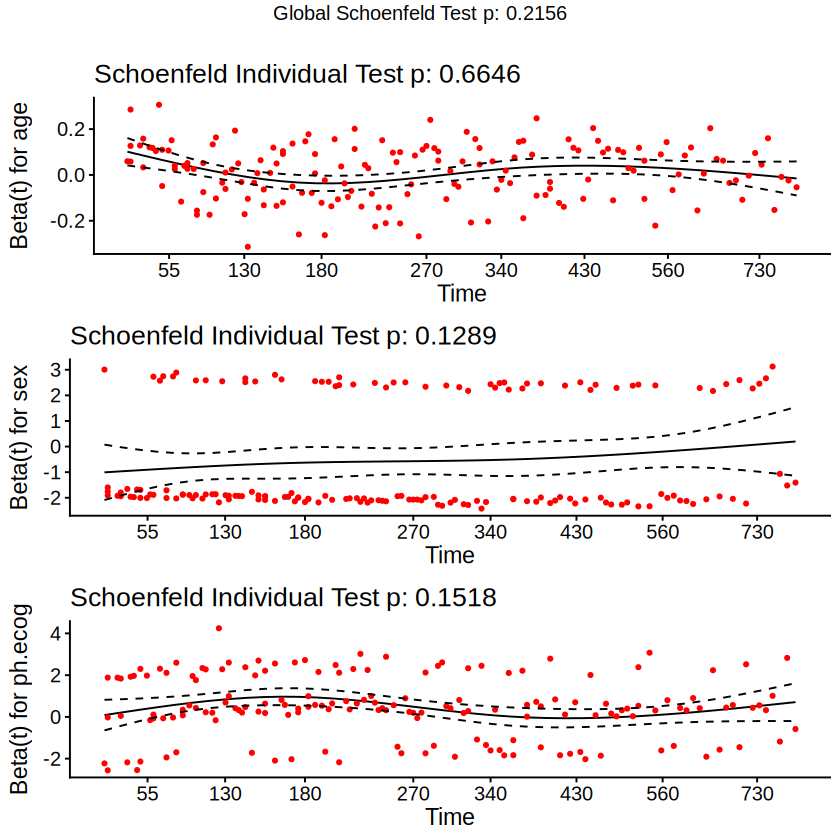

In [ ]:
# Test proportional hazards assumption
test_ph <- cox.zph(cox_fit)
print(test_ph)

# Plot the residuals to visually check assumption
ggcoxzph(test_ph)